# Smartphone ML Intelligence

## Part 6 — Specification-Based Value Analysis

### Objective

Estimate how each smartphone's actual market price compares with the price expected from its specifications.

The analysis uses out-of-fold price predictions so that each smartphone is evaluated by a model that was not trained on that smartphone.

This allows us to investigate:

- smartphones priced below their specification-based expectation
- smartphones carrying a price premium relative to their specifications
- value patterns across brands and market segments
- whether certain parts of the market systematically offer stronger specification value

The resulting value signals will later be incorporated into the recommendation engine.

### 1. Importing & Loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

In [2]:
DATA_PATH = Path("../data/processed/phones_clean.csv")

data = pd.read_csv(
    DATA_PATH,
    parse_dates=["launch_date"]
)

con = duckdb.connect()
con.register("phones", data)

query = """
SELECT *
FROM phones
WHERE availability=1
"""

phones = con.execute(query).df()


print(f"Rows: {phones.shape[0]}")
print(f"Columns: {phones.shape[1]}")

phones.head()

Rows: 161
Columns: 48


,name,brand,sale,processor_type,processor,fab,ram_type,rom_type,display_type,size,...,speaker,wireless_charging,ip_rating,price,availability,has_ultrawide,has_third_camera,has_fourth_camera,launch_year,phone_age_days
0,Galaxy A07,Samsung,Offline,Mediatek,Dimensity 6300,6,LPDDR4X,UFS 2.2,IPS LCD,6.7,...,Mono,False,54,20000,1,False,True,False,2026,263
1,Galaxy A17,Samsung,Offline,Exynos,1330,5,LPDDR4X,UFS 2.2,Amoled,6.7,...,Mono,False,54,28000,1,True,True,False,2025,423
2,Galaxy A27,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Mono,False,64,36000,1,True,True,False,2026,123
3,Galaxy A36,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5,UFS 2.2,Amoled,6.7,...,Stereo,False,67,36500,1,True,True,False,2025,603
4,Galaxy A37,Samsung,Offline,Exynos,1480,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Stereo,False,68,47000,1,True,True,False,2026,215


### 2. Defining Features & Target

In [3]:
excluded_features = [
    # Target
    "price",

    # Identifiers / descriptive text
    "name",
    "launch_date",
    "colors",
    "camera_sensor_name",

    # Avoid learning exact device / chipset identity
    "processor",

    # Benchmarks
    "antutu",
    "geekbench_single",
    "geekbench_multiple",

    # Market-position information
    "sale"
]

spec_features = [
    column
    for column in phones.columns
    if column not in excluded_features
]

X = phones[spec_features].copy()
y = phones["price"].copy()

print("Number of features:", len(spec_features))
print(spec_features)


Number of features: 38
['brand', 'processor_type', 'fab', 'ram_type', 'rom_type', 'display_type', 'size', 'curved_display', 'refresh_rate', 'hbm', 'protection', 'ppi', 'battery', 'charging_speed', 'thickness', 'back_material', 'frame_material', 'weight', 'camera_number', 'useful_camera_number', 'main', 'ultrawide', 'third', 'third_mp', 'fourth', 'fourth_mp', 'rear_video', 'front', 'front_video', 'speaker', 'wireless_charging', 'ip_rating', 'availability', 'has_ultrawide', 'has_third_camera', 'has_fourth_camera', 'launch_year', 'phone_age_days']


### 3. Identifying Features

In [4]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['fab', 'size', 'refresh_rate', 'hbm', 'ppi', 'battery', 'charging_speed', 'thickness', 'weight', 'camera_number', 'useful_camera_number', 'main', 'ultrawide', 'third_mp', 'fourth_mp', 'front', 'ip_rating', 'availability', 'launch_year', 'phone_age_days']

Categorical features:
['brand', 'processor_type', 'ram_type', 'rom_type', 'display_type', 'curved_display', 'protection', 'back_material', 'frame_material', 'third', 'fourth', 'rear_video', 'front_video', 'speaker', 'wireless_charging', 'has_ultrawide', 'has_third_camera', 'has_fourth_camera']


### 4. Preprocessing

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

### 5. Building Price Model

In [6]:
from sklearn.ensemble import GradientBoostingRegressor

price_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=2,
    min_samples_leaf=3,
    random_state=42
)

price_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", price_model)
])

### 6. Generating repeated Out-of-Fold predictions

In [7]:
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

oof_predictions = np.zeros(len(phones))
prediction_counts = np.zeros(len(phones))

for train_idx, test_idx in cv.split(X):

    model = clone(price_pipeline)

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    oof_predictions[test_idx] += predictions
    prediction_counts[test_idx] += 1

oof_predictions = (
    oof_predictions /
    prediction_counts
)

### 7. Evaluating Estimates

In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(
    y,
    oof_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y,
        oof_predictions
    )
)

r2 = r2_score(
    y,
    oof_predictions
)

print(f"OOF MAE  : ₹{mae:,.0f}")
print(f"OOF RMSE : ₹{rmse:,.0f}")
print(f"OOF R²   : {r2:.3f}")

OOF MAE  : ₹8,269
OOF RMSE : ₹13,851
OOF R²   : 0.873


### 8. Actual Value Analysis

In [9]:
value_analysis = phones.copy()

value_analysis["expected_price"] = (
    oof_predictions
)

value_analysis["value_gap"] = (
    value_analysis["expected_price"]
    - value_analysis["price"]
)

value_analysis["value_gap_pct"] = (
    value_analysis["value_gap"]
    / value_analysis["price"]
) * 100

In [10]:
value_analysis[
    [
        "name",
        "price",
        "expected_price",
        "value_gap",
        "value_gap_pct"
    ]
].sort_values(
    "value_gap_pct",
    ascending=False
)

,name,price,expected_price,value_gap,value_gap_pct
48,Moto Edge 70 Max,55000,104236.139516,49236.139516,89.520254
42,Lava Bold N2,13000,20786.660360,7786.660360,59.897387
55,Moto Signature,60000,92132.196680,32132.196680,53.553661
105,Realme GT 8 Pro,73000,107664.471436,34664.471436,47.485577
142,Vivo X200T,60000,87868.965337,27868.965337,46.448276
...,...,...,...,...,...
6,Galaxy A57,63000,41092.261664,-21907.738336,-34.774188
131,Tecno Pova 8 Pro,50000,32260.265196,-17739.734804,-35.479470
148,Xiaomi 17 Ultra,140000,86745.375266,-53254.624734,-38.039018
81,Pixel 10a,56000,33719.216925,-22280.783075,-39.787113


### 9. Inspecting Value Gap Description


In [11]:
value_analysis["value_gap_pct"].describe()

count    161.000000
mean       4.928263
std       20.705495
min      -45.296795
25%       -8.469825
50%        4.465844
75%       15.815306
max       89.520254
Name: value_gap_pct, dtype: float64

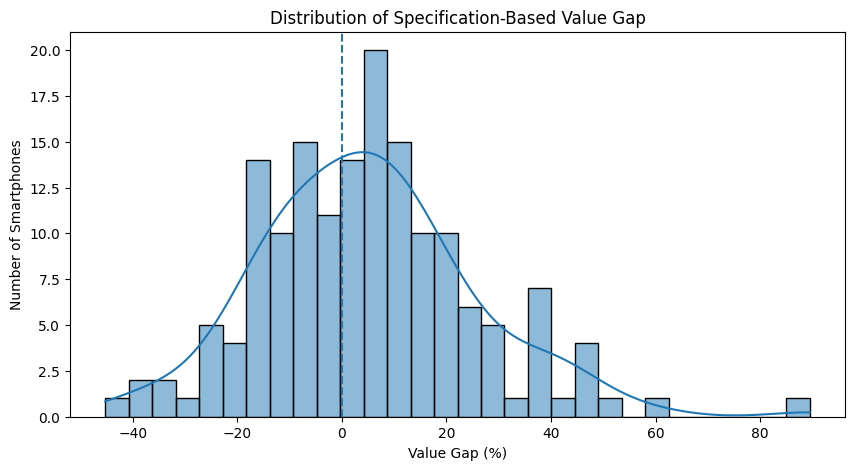

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    value_analysis["value_gap_pct"],
    bins=30,
    kde=True
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title("Distribution of Specification-Based Value Gap")
plt.xlabel("Value Gap (%)")
plt.ylabel("Number of Smartphones")

plt.show()

### 10. Actual price vs expected price

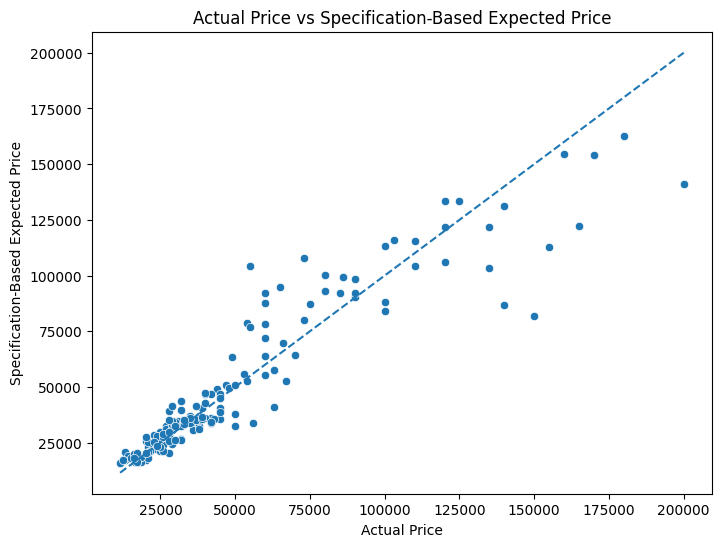

In [13]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=value_analysis,
    x="price",
    y="expected_price"
)

min_price = min(
    value_analysis["price"].min(),
    value_analysis["expected_price"].min()
)

max_price = max(
    value_analysis["price"].max(),
    value_analysis["expected_price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Specification-Based Expected Price")
plt.title("Actual Price vs Specification-Based Expected Price")

plt.show()

### 11. Value By Brand

In [14]:
brand_value = (
    value_analysis
    .groupby("brand")
    .agg(
        models=("name", "count"),
        avg_price=("price", "mean"),
        avg_value_gap=("value_gap", "mean"),
        avg_value_gap_pct=("value_gap_pct", "mean")
    )
    .sort_values(
        "avg_value_gap_pct",
        ascending=False
    )
)

brand_value = brand_value.round(2)

brand_value

,models,avg_price,avg_value_gap,avg_value_gap_pct
brand,,,,
Lava,4,16500.00,4445.10,30.06
Motorola,10,34000.00,9850.89,22.99
POCO,8,27812.50,3804.13,16.25
IQOO,8,40125.00,6610.95,13.19
Infinix,3,29333.33,3354.04,13.06
Realme,21,34666.67,3077.70,8.20
Tecno,7,28714.29,-758.79,2.91
Oppo,14,68142.86,-4394.77,1.92
Xiaomi,20,40650.00,-2069.26,1.90


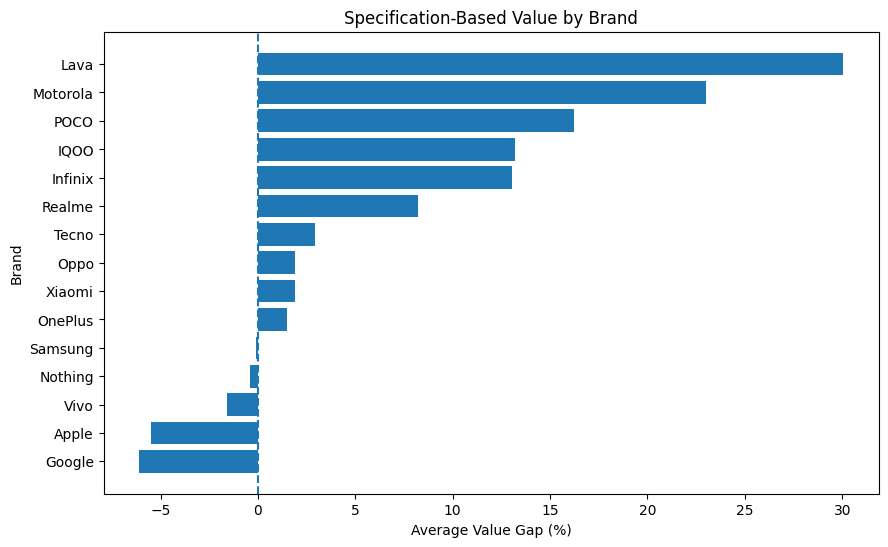

In [15]:
brand_plot = (
    brand_value[
        brand_value["models"] >= 3
    ]
    .sort_values("avg_value_gap_pct")
)

plt.figure(figsize=(10, 6))

plt.barh(
    brand_plot.index,
    brand_plot["avg_value_gap_pct"]
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Average Value Gap (%)")
plt.ylabel("Brand")
plt.title("Specification-Based Value by Brand")

plt.show()

### 12. Value By Price Range

In [16]:
price_bins = [
    0,
    15000,
    30000,
    60000,
    100000,
    np.inf
]

price_labels = [
    "Budget",
    "Mid-Range",
    "Upper Mid-Range",
    "Premium",
    "Ultra-Premium"
]

value_analysis["price_range"] = pd.cut(
    value_analysis["price"],
    bins=price_bins,
    labels=price_labels,
    right=False
)

In [17]:
price_range_value = (
    value_analysis
    .groupby(
        "price_range",
        observed=True
    )
    .agg(
        models=("name", "count"),
        avg_price=("price", "mean"),
        avg_value_gap=("value_gap", "mean"),
        avg_value_gap_pct=("value_gap_pct", "mean")
    )
)

price_range_value.round(2)

,models,avg_price,avg_value_gap,avg_value_gap_pct
price_range,,,,
Budget,6,12750.00,5123.30,40.19
Mid-Range,57,22552.63,1574.74,7.35
Upper Mid-Range,54,40731.48,648.85,1.12
Premium,23,72260.87,9025.24,12.80
Ultra-Premium,21,135142.86,-16596.14,-10.54


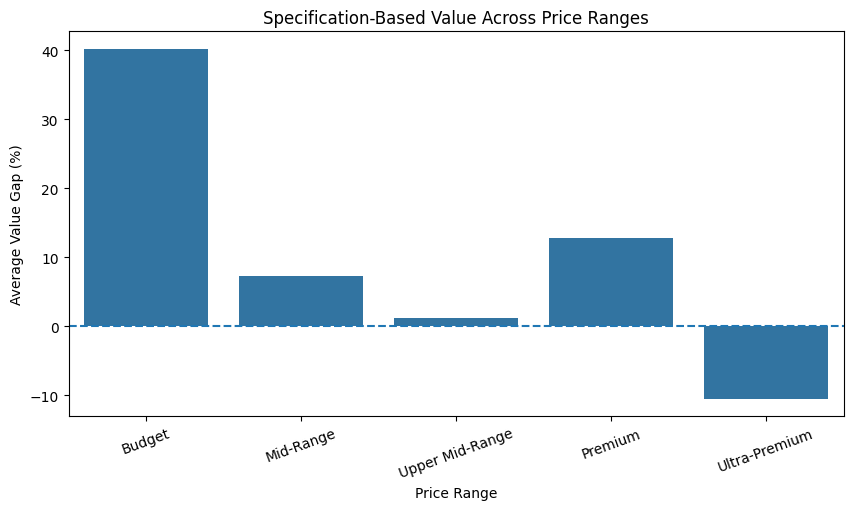

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=price_range_value.reset_index(),
    x="price_range",
    y="avg_value_gap_pct"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Price Range")
plt.ylabel("Average Value Gap (%)")
plt.title("Specification-Based Value Across Price Ranges")

plt.xticks(rotation=20)

plt.show()

### 13. Creating The Final Value Score (0-100%)

In [19]:
value_analysis["value_score"] = (
    value_analysis["value_gap_pct"]
    .rank(
        pct=True,
        method="average"
    )
    * 100
)

value_analysis["value_score"] = (
    value_analysis["value_score"]
    .round(1)
)

In [20]:
final_value_ranking = (
    value_analysis[
        [
            "name",
            "brand",
            "price",
            "expected_price",
            "value_gap",
            "value_gap_pct",
            "value_score"
        ]
    ]
    .sort_values(
        "value_score",
        ascending=False
    )
    .reset_index(drop=True)
)

final_value_ranking[
    [
        "expected_price",
        "value_gap",
        "value_gap_pct",
        "value_score"
    ]
] = final_value_ranking[
    [
        "expected_price",
        "value_gap",
        "value_gap_pct",
        "value_score"
    ]
].round(2)

with pd.option_context(
    "display.max_rows",
    None
):
    display(final_value_ranking)

,name,brand,price,expected_price,value_gap,value_gap_pct,value_score
0,Moto Edge 70 Max,Motorola,55000,104236.14,49236.14,89.52,100.0
1,Lava Bold N2,Lava,13000,20786.66,7786.66,59.90,99.4
2,Moto Signature,Motorola,60000,92132.20,32132.20,53.55,98.8
3,Realme GT 8 Pro,Realme,73000,107664.47,34664.47,47.49,98.1
4,Vivo X200T,Vivo,60000,87868.97,27868.97,46.45,97.5
5,Xiaomi 15,Xiaomi,65000,94692.63,29692.63,45.68,96.9
6,Iqoo 15R,IQOO,54000,78619.25,24619.25,45.59,96.3
7,Realme P4 Pro,Realme,29000,41411.85,12411.85,42.80,95.7
8,Galaxy F56,Samsung,28000,39132.28,11132.28,39.76,95.0
9,Oneplus 13s,OnePlus,55000,76800.76,21800.76,39.64,94.4


In [21]:
OUTPUT_PATH = (
    DATA_PATH.parent /
    "phones_with_value_scores.csv"
)

value_analysis.to_csv(
    OUTPUT_PATH,
    index=False
)

print(
    "Saved:",
    OUTPUT_PATH
)

Saved: ..\data\processed\phones_with_value_scores.csv
